# NASA EPSCoR Progress: Characterization of Isolated EOM Performance
### 20261023 - *Tyndale Stutzman*
---

## Introduction:

This notebook aims to diagnose the performance of a repaired EOM against that of a fully functioning one. More specifically, the EOM to be characterized is a [Newport 4004](https://api.p1.mks.com/medias/sys_master/images/images/h65/hcc/8797007839262/400X-and-406X-User-Manual-Rev-J.pdf) modulator, compared against a [Thorlabs EO-PM-NR-C1 EOM](https://www.thorlabs.com/item/EO-PM-NR-C1). In the process of preparing the 4004 to accomodate temperature stabilizing components, the crystal was removed, inadvertently breaking the wire bonded electrodes. To fix this, 1mil platinum wire was manually bonded to the crystal with [Leitsilber 200](https://www.fishersci.com/shop/products/leitsilver/NC9368358) silver cement. Before building this notebook, the EOM has been demonstrated to function as expected, up to a few $\text{ kHz}$, however behavior beyond that limit is unknown. A few photos of the manual wire bonded repair are below.<!-- 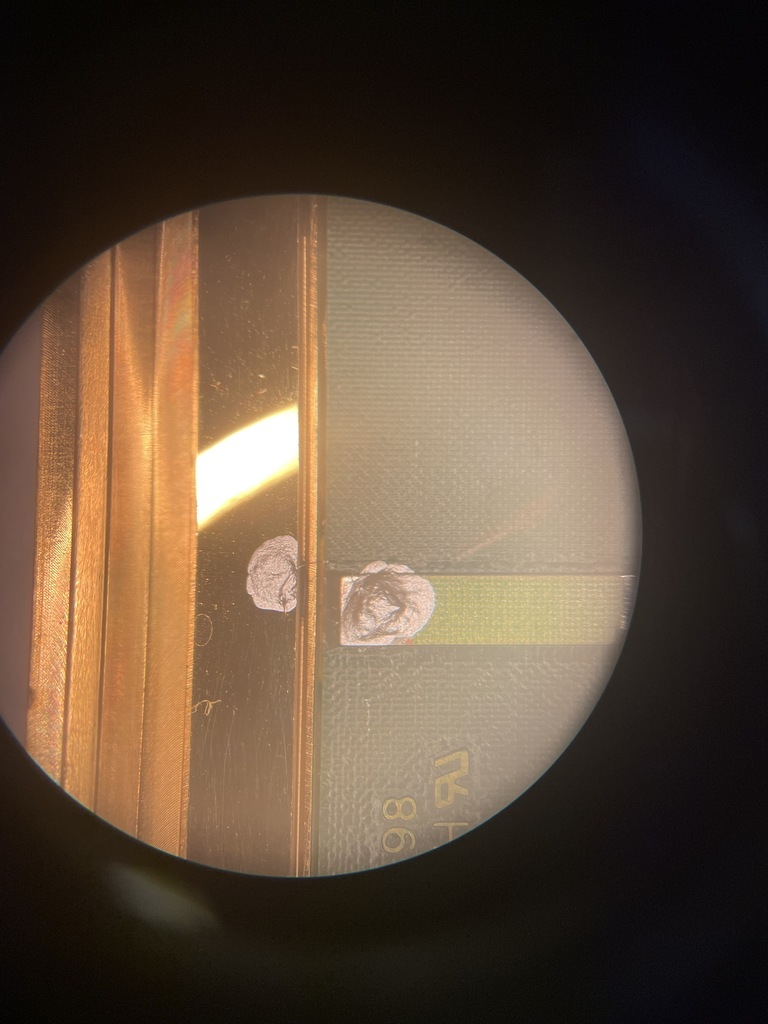 -->

## Table of Contents

1. [Background](#background)
1. [Setup](#setup)
   1. [Environment & Packages](#env)
   1. [Parameter Configuration](#conf)
   1. [Connect Devices](#connect)
      1. [Red Pitaya](#RP)
      1. [PAX Polarimeter](#PAX)
   1. [Run Recorder](#recorder)
1. [Characterization](#char)
   1. [Drive Check: OUT1 at the tee](#vdrive)
   1. [$V_{\pi}$ in OUT1 volts](#vpi)
   1. [Frequency Response](#frequencyresponse)
       1. [Step Response](#freq)
       1. [Swept Sine](#sweep)
       1. [FPGA Network Analyzer](#network)
   1. [Stability & Drift](#drift)
1. [Save Data](#save)
1. [Analysis](#analysis)

<a id="setup"></a>
## Setup


<a id="env"></a>
### Environment & Packages

To get started, enter the appropriate repository environment and run this notebook from this local folder, `notebooks/`.

In [35]:
import sys
from pathlib import Path
from importlib.metadata import version

src = (Path("python") if Path("python").is_dir() else Path("../python")).resolve()
assert (src / "instruments").is_dir(), "Start in the repo root or notebooks/"
for directory in (src, src.parent):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

print(f"Python {sys.version.split()[0]} | {sys.executable}")
print({name: version(name) for name in ("numpy", "scipy", "pyrpl", "yaqc")})

Python 3.10.20 | /home/augustus/miniconda3/envs/jl-env/bin/python3.10
{'numpy': '2.2.5', 'scipy': '1.15.3', 'pyrpl': '0.9.8.0', 'yaqc': '2023.6.0'}


<a id="conf"></a>
### Parameter Configuration

Everything here is typed by hand: connections, the RP jumper positions, the HV safety limit and the bench log.
Bench facts live in `bench`, with their source; correct them whenever something on the bench changes.

**Wiring (2026-10-28):** OUT1 → BNC tee → preamp → 3211 → EOM, and tee → IN2 (LV). PD → IN1 (LV).
The 3211 monitor is no longer recorded (it reports demand, not delivered HV).

In [36]:
# Connections; the SSH key pin comes from the existing EOM tool.
rp_hostname = "192.168.1.98"
rp_config = "scope_config"
ssh_host_key_sha256 = "W5g8Qcvu7r+8mMQZInHzNLpvOpYsvnCvo5hwYkWJCRY"
frequency_correction = 1.0  # Nominal RP clock, not a measurement
pax_daemon_config_path = src / "polarization_locking/hardware/pax1000.toml"
pax_measurement_wait_s = 0.06
pax_fresh_read_timeout_s = 5.0
results_directory = src.parent / "experiments" / "_local"

wavelength_nm = 830.0
eom_under_test = "Newport 4004 EOM (repaired)"

# RP inputs: jumper positions as set. IN1 = PD, IN2 = OUT1 at the tee.
rp_jumpers = {"in1": "LV", "in2": "LV"}
rp_full_scale_v = {k: {"LV": 1.0, "HV": 20.0}[v] for k, v in rp_jumpers.items()}

# HV safety: 3211 output per OUT1 command volt, ONE DC point with a DMM in place of the EOM
# (agent_dc_hold_20261028T164028Z). Full 3211 range allowed, no margin (Tyndale, 2026-10-28).
hv_per_command_v = 406.0
command_limit_v = 0.48
assert hv_per_command_v * command_limit_v <= 200, "Predicted HV exceeds the 200 V working limit"

# Bench log: earlier hand measurements with their source. Fill every None before acquiring.
bench = {
    "tec_setpoint": "10.75 kOhm",     # As set on the controller, with units
    "thermistor_reading": "10.07 kOhm, stabilized (operator 2026-10-28: both correct; it locks at 10.07 although set to 10.75)",
    "hwp_angle_deg": "278 degrees",            # Dial reading
    "preamp_setting": "as found 2026-10-28; DMM 3.148 V out; input 0.354 V unloaded (x8.89) or ~0.304 V at tee (x10.4), unresolved",
    "amp3211_gain_setting": "as found 2026-10-28; DMM: 121.8 V out for 3.148 V in (x38.7), DMM replacing EOM",
    "amp3211_bias_setting": "zeroed by operator at 0 V input, 2026-10-28",
    "in2_jumper": "LV (operator, 2026-10-28)",
    "pd_gain": "PDA100A2 at 0 dB (operator, 2026-10-28 ~22:04 UTC; was 10 dB before)",
    "analog_check": "STALE (2026-10-28): was ~50 mV undriven; later RP runs read 18-100 mV at 0 V command depending on PD gain and fringe drift",      # What the scope showed, typed by hand
}
print(f"OUT1 limit ±{command_limit_v} V ≈ ±{hv_per_command_v * command_limit_v:.0f} V HV | "
      f"unfilled bench log: {[k for k, v in bench.items() if v is None] or 'none'}")

OUT1 limit ±0.48 V ≈ ±195 V HV | unfilled bench log: none


<a id="connect"></a>
### Connect Devices

This experiment uses the Red Pitaya and the Thorlabs PAX polarimeter. 

<a id="RP"></a>
#### Red Pitaya

In [37]:
# Refresh the edited wrapper after closing this notebook's previous connection.
from importlib import reload
import instruments.red_pitaya as rp_interface
import instruments._rp_drive as rp_drive_module

reload(rp_drive_module)  # drive_session imports this at call time; reload picks up driver edits

if "rp" in globals():
    rp.close()
RedPitaya = reload(rp_interface).RedPitaya
rp = RedPitaya(rp_hostname, profile=rp_config)
rp.attach_monitor()  # Smoke test only: does not initialize drive outputs.
rp.read_status()

{'host': '192.168.1.98',
 'mode': 'monitor_only',
 'monitor_port': 2223,
 'preferred_monitor_port': 2223,
 'scope_registers': {'0x40100004': 0,
  '0x40100010': 16384,
  '0x40100014': 65536,
  '0x40100028': 0,
  '0x40380000': 10,
  '0x40390000': 11},
 'requested_monotonic_s': 133459.39716084,
 'received_monotonic_s': 133459.398748907,
 'received_utc': '2026-10-28T22:29:59.673986+00:00'}

<a id="PAX"></a>
#### PAX Polarimeter

In [38]:
'''

from importlib import reload
import instruments.pax as pax_interface

PAX = reload(pax_interface).PAX
with PAX.local_session(config_path=pax_daemon_config_path,
                       measurement_wait_s=pax_measurement_wait_s) as pax:
    pax.set_wavelength(wavelength_nm)
    display(pax.read_status())
    pax_raw = pax.read_fresh(timeout_s=pax_fresh_read_timeout_s)

pax_raw

'''

'\n\nfrom importlib import reload\nimport instruments.pax as pax_interface\n\nPAX = reload(pax_interface).PAX\nwith PAX.local_session(config_path=pax_daemon_config_path,\n                       measurement_wait_s=pax_measurement_wait_s) as pax:\n    pax.set_wavelength(wavelength_nm)\n    display(pax.read_status())\n    pax_raw = pax.read_fresh(timeout_s=pax_fresh_read_timeout_s)\n\npax_raw\n\n'

<a id="recorder"></a>
### Run Recorder

Plumbing for every RP run below: one drive session, raw counts and metadata saved after each capture
(including failed or interrupted ones), outputs returned to zero/off at the end. `raw_look` plots every
sample with no processing. Stages: `"off"` (outputs off), `"dc_points"` (DC steps on OUT1), `"sine"` (0 V offset), `"square"` (square wave on a DC offset), `"sweep"` (stepped sine on a DC offset, one buffer per frequency), `"network"` (FPGA network analyzer on a DC offset; no raw waveforms).

In [39]:
import json, subprocess, time
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt

recorder_cell = globals().get("_ih", ["Not available outside IPython"])[-1]  # this cell's text, saved with every run

def rp_run(stage, *, wiring, dc_command_v=(), sine=None, square=None, sweep=None, network=None):
    """Drive OUT1 for one stage and save raw IN1/IN2 counts. Returns the run folder."""
    missing = [k for k, v in bench.items() if v is None]
    assert not missing and wiring, f"Fill the bench log and type the wiring first: {missing}"
    if "rp" in globals():
        rp.close()  # Release the passive smoke-test connection before active initialization.
    run = results_directory / f"{stage}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}"
    run.mkdir(parents=True)
    git = lambda *a: subprocess.run(["git", "-C", str(src.parent), *a], capture_output=True, text=True).stdout.strip()
    record = {"status": "running", "stage": stage, "wiring": wiring, "bench": bench, "jumpers": rp_jumpers,
              "full_scale_v": rp_full_scale_v, "dc_command_v": list(dc_command_v), "sine": sine, "square": square, "sweep": sweep, "network": network,
              "hv_per_command_v": hv_per_command_v, "command_limit_v": command_limit_v,
              "eom": eom_under_test, "wavelength_nm": wavelength_nm,
              "started_utc": datetime.now(timezone.utc).isoformat(), "python": sys.version,
              "packages": {name: version(name) for name in ("numpy", "pyrpl")},
              "git": {"commit": git("rev-parse", "HEAD"), "dirty": git("status", "--porcelain")},
              "source_text": {name: (src / "instruments" / name).read_text() for name in ("_rp_drive.py", "red_pitaya.py")},
              "calling_cell": globals().get("_ih", ["Not available outside IPython"])[-1],
              "recorder_source": recorder_cell, "captures": []}
    save = lambda: (run / "metadata.json").write_text(json.dumps(record, indent=1, default=str))
    save()
    raw = {}
    def keep(name, capture, command):
        raw[name] = capture["raw_counts"]
        record["captures"].append({"name": name, "command": command, "metadata": capture["metadata"]})
        np.savez_compressed(run / "raw.npz", **raw)
        save()
        print(name, capture["metadata"]["issues"] or "ok", flush=True)
    # Fast drive only at small amplitude: the 3211 must charge the EOM capacitance (I = C dV/dt).
    freq_limits, max_peak = {"square": ([0.5, 5e3], 0.05), "sweep": ([5.0, 2e6], 0.05),
                             "network": ([5.0, 50e6], 0.05)}.get(stage, ([0.5, 2.0], command_limit_v))
    drive = RedPitaya.drive_session(rp_hostname, profile=rp_config, ssh_host_key_sha256=ssh_host_key_sha256,
        command_limits_v={"out1": [-command_limit_v, command_limit_v]}, frequency_limits_hz=freq_limits,
        max_peak_v=max_peak, frequency_correction=frequency_correction)
    try:
        with drive:
            if stage == "off":
                keep("off", drive.capture(decimation=1024, full_scale_v=rp_full_scale_v), None)
            elif stage == "dc_points":
                drive.set_waveform("out1", waveform="dc", offset_v=0.0, peak_v=0, frequency_hz=0)
                for i, v in enumerate(dc_command_v):
                    drive.set_dc_offset("out1", offset_v=v, ramp_s=0.5)
                    time.sleep(1.0)
                    keep(f"dc{i}_{v:+.3f}", drive.capture(decimation=1024, full_scale_v=rp_full_scale_v), drive.last_command)
            elif stage == "sine":
                drive.set_waveform("out1", offset_v=0.0, peak_v=sine["peak_v"], frequency_hz=sine["frequency_hz"], ramp_s=0.5)
                time.sleep(sine["settle_s"])
                for i in range(sine["buffers"]):  # 65536 -> 8.59 s per buffer; buffers are not contiguous
                    keep(f"sine{i}", drive.capture(decimation=65536, full_scale_v=rp_full_scale_v), drive.last_command)
            elif stage == "square":
                drive.set_waveform("out1", waveform="square", offset_v=square["offset_v"], peak_v=square["peak_v"],
                                   frequency_hz=square["frequency_hz"], ramp_s=0.5)
                time.sleep(square["settle_s"])
                for i in range(square["buffers"]):
                    keep(f"square{i}", drive.capture(decimation=square["decimation"], full_scale_v=rp_full_scale_v), drive.last_command)
            elif stage == "sweep":  # one buffer per frequency, holding >= min_cycles cycles
                decades = np.log10(sweep["stop_hz"] / sweep["start_hz"])
                for i, f in enumerate(np.geomspace(sweep["start_hz"], sweep["stop_hz"], int(decades * sweep["points_per_decade"]) + 1)):
                    dec = next(d for d in (2**k for k in range(17)) if 16384 * 8e-9 * d >= sweep["min_cycles"] / f or d == 65536)
                    if i == 0:  # ramp the bias once; afterwards only the frequency changes (route and bias held)
                        drive.set_waveform("out1", offset_v=sweep["offset_v"], peak_v=sweep["peak_v"], frequency_hz=f, ramp_s=0.5)
                    else:
                        drive.set_frequency("out1", frequency_hz=f)
                    time.sleep(max(0.05, 5 / f))
                    keep(f"f{i:02d}", drive.capture(decimation=dec, full_scale_v=rp_full_scale_v), drive.last_command)
            elif stage == "network":  # FPGA lock-in sweep; PD and tee measured in two passes on the same bias
                drive.set_waveform("out1", waveform="dc", offset_v=network["offset_v"], peak_v=0, frequency_hz=0, ramp_s=0.5)
                time.sleep(1.0)
                decades = np.log10(network["stop_hz"] / network["start_hz"])
                freqs = np.geomspace(network["start_hz"], network["stop_hz"], int(decades * network["points_per_decade"]) + 1)
                for ch in ("in1", "in2"):
                    na = drive.network_sweep("out1", input=ch, frequencies_hz=freqs, amplitude_v=network["amplitude_v"],
                                             q=network["q"], max_rbw_hz=network["max_rbw_hz"])
                    raw[f"na_{ch}_frequency_hz"], raw[f"na_{ch}_response"] = np.array(na.pop("frequency_hz")), np.array(na.pop("response"))
                    record[f"na_{ch}"] = na
                    np.savez_compressed(run / "raw.npz", **raw)
                    save()
                    print(f"{ch} done", flush=True)
            else:
                raise ValueError(stage)
        record["status"] = "completed"
    except BaseException as error:
        record.update(status="interrupted" if isinstance(error, KeyboardInterrupt) else "failed",
                      error=f"{type(error).__name__}: {error}")
        partial = drive.last_capture or {}
        if partial and not any(c["metadata"] is partial.get("metadata") for c in record["captures"]):
            record["partial_capture_metadata"] = partial.get("metadata")  # Also when it failed before readout.
            if any(k in partial for k in ("raw_in1", "raw_in2")):
                raw.update({f"partial_{k}": partial[k] for k in ("raw_in1", "raw_in2") if k in partial})
                np.savez_compressed(run / "raw.npz", **raw)
        raise
    finally:
        record.update(connection=drive.connection_evidence, command_last=drive.last_command,
                      cleanup=drive.cleanup_evidence, finished_utc=datetime.now(timezone.utc).isoformat())
        save()
        print(f"{record['status']}; cleanup={drive.cleanup_evidence.get('status')}; saved to {run}")
    return run

def raw_look(run):
    """Every saved sample, no processing. Reads the files, not memory. partial_* arrays: inspect by hand."""
    saved = json.loads((run / "metadata.json").read_text())
    fs = np.array([saved["full_scale_v"][k] for k in ("in1", "in2")])[:, None]
    with np.load(run / "raw.npz") as z:
        volts = {c["name"]: z[c["name"]] / 8192 * fs for c in saved["captures"]}
    if saved["stage"] == "sweep":  # four of the buffers, first three drive cycles each
        names = list(volts)
        fig, axes = plt.subplots(2, 4, figsize=(14, 6))
        for col, name in enumerate(names[::max(1, (len(names) - 1) // 3)][:3] + names[-1:]):
            c = next(c for c in saved["captures"] if c["name"] == name)
            f, dt = c["command"]["actual"]["frequency_hz"], c["metadata"]["scope"]["sample_interval_s"]
            n = min(len(volts[name][0]), int(3 / (f * dt)) + 1)
            t_us = np.arange(n) * dt * 1e6
            axes[0, col].plot(t_us, volts[name][1][:n], lw=0.6); axes[0, col].set_title(f"{f:,.0f} Hz")
            axes[1, col].plot(t_us, volts[name][0][:n], lw=0.6); axes[1, col].set_xlabel("Time (µs)")
        axes[0, 0].set_ylabel("OUT1 at tee, IN2 raw (V)"); axes[1, 0].set_ylabel("PD, IN1 raw (V)")
    elif saved["stage"] == "square":  # time traces: OUT1 edges on top, PD response below
        fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
        for i, (name, v) in enumerate(volts.items()):
            dt = next(c["metadata"]["scope"]["sample_interval_s"] for c in saved["captures"] if c["name"] == name)
            t_us = np.arange(v.shape[1]) * dt * 1e6  # nominal scope clock
            top.plot(t_us, v[1], lw=0.6, color=f"C{i}", label=name)
            bottom.plot(t_us, v[0], lw=0.6, color=f"C{i}")
        top.set(ylabel="OUT1 at tee, IN2 raw (V)"); top.legend(fontsize=7)
        bottom.set(xlabel="Time within buffer (µs)", ylabel="PD, IN1 raw (V)")
        for a in (top, bottom):
            a.minorticks_on(); a.grid(which="both", alpha=0.3)
    elif saved["stage"] == "sine":
        fig, (top, xy) = plt.subplots(2, 1, figsize=(10, 8))
        for i, (name, v) in enumerate(volts.items()):
            dt = next(c["metadata"]["scope"]["sample_interval_s"] for c in saved["captures"] if c["name"] == name)
            top.plot(np.arange(v.shape[1]) * dt, v[0], lw=0.4, color=f"C{i}", label=name)  # nominal scope clock
            xy.plot(v[1], v[0], ",", color=f"C{i}", alpha=0.4)
        top.set(xlabel="Time within buffer (s)", ylabel="PD, IN1 raw (V)"); top.legend(fontsize=7)
        xy.set(xlabel="OUT1 at tee, IN2 raw (V)", ylabel="PD, IN1 raw (V)", title="Raw XY, one colour per buffer")
    else:  # DC steps. Left: tee vs command readback (0 V when outputs are off). Right: PD in step order.
        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        for i, c in enumerate(saved["captures"]):
            v, cmd = volts[c["name"]], (c["command"] or {"actual": {"offset_v": 0.0}})["actual"]["offset_v"]
            ax[0].plot(np.full(v.shape[1], cmd), v[1], ".", ms=2, color=f"C{i}", label=c["name"])
            ax[1].plot(np.full(v.shape[1], i), v[0], ".", ms=2, color=f"C{i}")
        lim = saved["command_limit_v"]
        ax[0].plot([-lim, lim], [-lim, lim], "k:", lw=0.8, label="tee = command")
        ax[0].set(xlabel="OUT1 command (V)", ylabel="OUT1 at tee, IN2 raw (V)"); ax[0].legend(fontsize=7)
        ax[1].set(xticks=range(len(volts)), xticklabels=list(volts), ylabel="PD, IN1 raw (V)", title="PD in step order")
        ax[1].tick_params(axis="x", rotation=45)
    fig.suptitle(f"{run.name}: raw samples, no processing")
    plt.tight_layout(); plt.show()

<a id="char"></a>
## EOM Characterization

The objective of the following experiments is to determine the performance capabilities of the repaired Newport 4004 EOM. This will aid in the development of calibration measurements for the development of the high-speed dual-EOM polarimeter. 

<a id="vdrive"></a>
### Drive Check: OUT1 at the tee

**Question:** Does OUT1 deliver the commanded voltage into the preamp, on both signs, and does the PD follow each step?

**Prediction:** IN2 ≈ 1.012 × command + 2 mV, the same on both signs (agent_tee_cal_20261028T180054Z). The PD moves at every step and returns to the same level at each 0 V.

**Caveats:**
-  IN2's LV gain is not independently calibrated; a DMM at the tee while a DC level is held settles it.
-  One pass of steps cannot separate slow drift from hysteresis; the repeated 0 V points show how large either is.
-  ±0.4 V command ≈ ±162 V predicted at the EOM.

**Notable Decisions:**
- (1) Each DC level is the mean of its 134 ms buffer; tee gain from the ±0.4 V points, zero from the mean of the 0 V points; report the worst miss from that line and the PD spread at 0 V. Simplest numeric check that the drive works.

**Simplest estimate:** Read IN2 at the +0.4 and −0.4 V steps off the raw plot; their difference ÷ 0.8 is the tee gain.

<!-- Decision log: 1 approved TS 2026-10-28 (asked in chat). -->

In [40]:
drive_run = rp_run("dc_points", wiring="Out1 -> In2 and preamp, preamp -> 3211 -> 4004 EOM",  # Type what is connected now
                   dc_command_v=[0.0, 0.2, 0.4, 0.0, -0.2, -0.4, 0.0])

INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


dc0_+0.000 ok
dc1_+0.200 ok
dc2_+0.400 ok
dc3_+0.000 ok
dc4_-0.200 ok
dc5_-0.400 ok
dc6_+0.000 ok
completed; cleanup=COMPLETED; saved to /home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/dc_points_20261028T223008Z


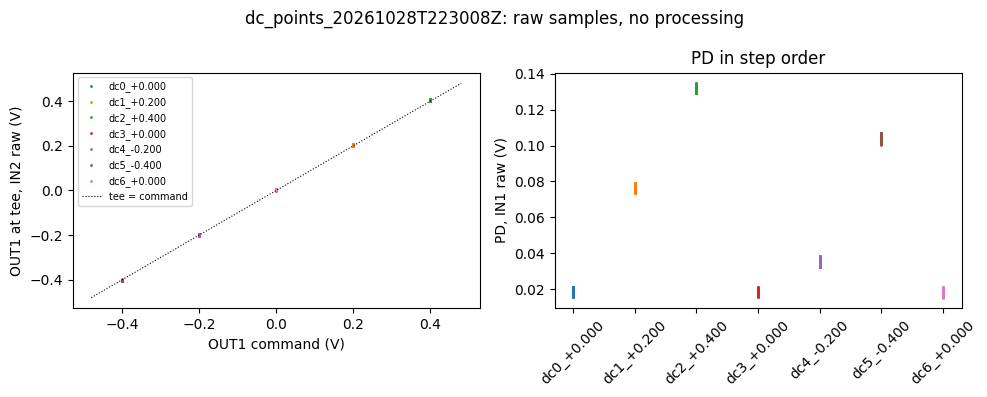

In [41]:
raw_look(drive_run)

In [42]:
# Drive check numbers (Decision 1: mean of each DC buffer).
drive_meta = json.loads((drive_run / "metadata.json").read_text())
fs = np.array([drive_meta["full_scale_v"]["in1"], drive_meta["full_scale_v"]["in2"]])
pts = []
with np.load(drive_run / "raw.npz") as z:
    for c in drive_meta["captures"]:
        pd_mean, tee_mean = z[c["name"]].mean(axis=1) / 8192 * fs
        pts.append((c["command"]["actual"]["offset_v"], pd_mean, tee_mean))
cmd, pd, tee = np.array(pts).T
tee_gain = (tee[cmd.argmax()] - tee[cmd.argmin()]) / (cmd.max() - cmd.min())  # two-point, ±0.4 V
tee_zero = tee[cmd == 0].mean()
drive_check = {"run": drive_run.name, "tee_gain": tee_gain, "tee_zero_v": tee_zero,
               "worst_line_miss_v": np.abs(tee - (tee_zero + tee_gain * cmd)).max(), "pd_at_0V_spread_v": np.ptp(pd[cmd == 0])}
for c, p, t in pts:
    print(f"command {c:+.3f} V -> tee {t:+.4f} V, PD {p:.4f} V")
print(f"Tee = {tee_gain:.4f} x command {tee_zero*1e3:+.1f} mV | worst miss from that line {drive_check['worst_line_miss_v']*1e3:.1f} mV"
      f" | PD at 0 V repeats to {drive_check['pd_at_0V_spread_v']*1e3:.1f} mV")

command +0.000 V -> tee +0.0022 V, PD 0.0185 V
command +0.200 V -> tee +0.2047 V, PD 0.0765 V
command +0.400 V -> tee +0.4072 V, PD 0.1318 V
command +0.000 V -> tee +0.0022 V, PD 0.0183 V
command -0.200 V -> tee -0.1998 V, PD 0.0352 V
command -0.400 V -> tee -0.4023 V, PD 0.1038 V
command +0.000 V -> tee +0.0022 V, PD 0.0184 V
Tee = 1.0118 x command +2.2 mV | worst miss from that line 0.3 mV | PD at 0 V repeats to 0.2 mV


<a id="vpi"></a>
### $V_{\pi}$ in OUT1 volts

**Question:** What OUT1 voltage, measured at the tee into the preamp, changes the EOM retardance by $\pi$?

**Prediction:** $V_\pi \approx 0.51$ V at the tee (0.50 V command × 1.012). PD vs OUT1 traces one cosine fringe; up and down sweeps overlap.

**Derivation:** For a retarder between polarizers,
$$I(V) = A + B\cos\!\left(\Gamma_0 + \pi V/V_\pi\right).$$
The HWP and analyzer angles set only $A$ and $B$ (contrast); the fringe repeats every $2V_\pi$ regardless. The PD crosses the halfway height $A = (I_\text{peak}+I_\text{trough})/2$ every $V_\pi$, so two neighbouring crossings are $V_\pi$ apart. Crossings, not peaks, because the fringe is steepest there: one sample places a crossing about 8× more precisely than a flat peak. A 0.48 V peak sweep (≈ ±195 V at the EOM, ≈ 1.9 $V_\pi$ peak to peak) usually holds a peak, a trough and two crossings.

**Caveats:**
- The window can miss a crossing (about 1 run in 6, depending on where $\Gamma_0$ sits). Check the raw XY first.
- 3211 clipping would only show as a kink or flat stretch at the ends of the XY fringe (no HV probe; the monitor shows demand).
- $V_\pi$ in OUT1 volts holds only for the logged preamp, 3211, cables and TEC (`bench`).
- $\Gamma_0$ drift moves up and down sweeps in opposite directions; lag after OUT1 would open a loop.
- Only one fringe is in range, so linearity of $\Gamma$ in $V$ beyond it is untested.

**Notable Decisions:**
- (2) Halfway height = (max + min)/2 of the raw PD, per buffer.
- (3) Crossing = mean OUT1 of samples within ±2 mV of halfway; the two clusters split at the largest gap.
- (4) $V_\pi$ in command volts = $V_\pi$ at the tee ÷ tee gain (Drive Check), which cancels IN2's uncalibrated gain.
- (14) Bias for the step, sweep and network tests = right crossing of the last Vπ buffer, in command volts via the Drive Check line. The fringe drifts, so it is re-read every Vπ run instead of hard-coded.

**Simplest estimate:** On the raw XY plot, draw a line at the halfway height and read the two crossing x-values; their difference is $V_\pi$.

<!-- Decision log: 2, 3 approved TS 2026-10-28 (asked in chat); adversary: extremes noise and band choice each move Vpi <= 1.5 mV.
4 PENDING approval (implemented in the Vpi numbers cell).
14 approved TS 2026-10-28 ("do not hard code the bias"); recorded as a Decision at the 2026-10-28 archivist close-out.
Proposed, not approved: split up/down sweeps (exploratory: agree to ~1 mV). -->

In [43]:
vpi_sine = {"peak_v": 0.48, "frequency_hz": 1.0, "buffers": 5, "settle_s": 2.0}  # 0.48 V ≈ 195 V predicted
vpi_run = rp_run("sine", wiring="Out1 -> In2 and preamp, preamp -> 3211 -> 4004 EOM", sine=vpi_sine)  # Type what is connected now

INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


sine0 ok
sine1 ok
sine2 ok
sine3 ok
sine4 ok
completed; cleanup=COMPLETED; saved to /home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/sine_20261028T223032Z


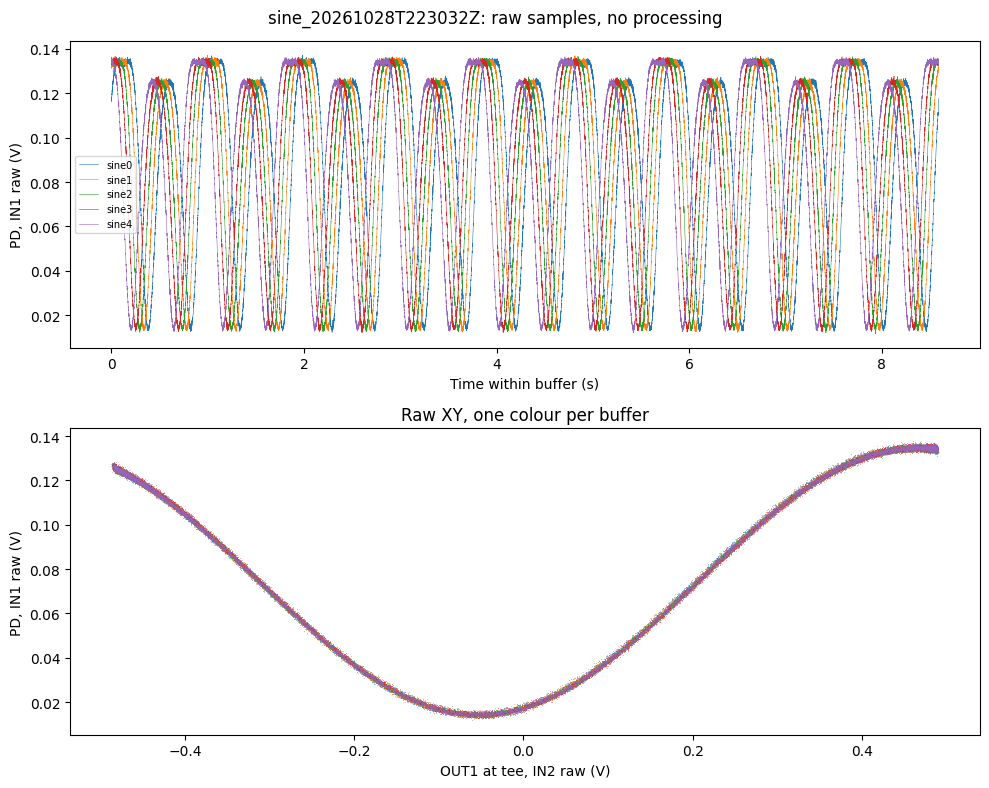

In [44]:
raw_look(vpi_run)

In [45]:
# Vπ numbers (Decisions 2-4): per buffer, no averaging across buffers.
def fringe_rows(run):
    """Per buffer: time, PD peak/trough (raw extremes), halfway height, two crossings and Vπ at the tee."""
    meta = json.loads((run / "metadata.json").read_text())
    fs = np.array([[meta["full_scale_v"]["in1"]], [meta["full_scale_v"]["in2"]]])
    t0, rows = meta["captures"][0]["metadata"]["requested_monotonic_s"], []
    with np.load(run / "raw.npz") as z:
        for c in meta["captures"]:
            pd, tee = z[c["name"]] / 8192 * fs
            half = (pd.max() + pd.min()) / 2
            xs = np.sort(tee[np.abs(pd - half) < 0.002])   # samples near the halfway height
            gap = np.diff(xs).argmax()                    # the two crossings are the two clusters
            left, right = xs[:gap + 1].mean(), xs[gap + 1:].mean()
            rows.append({"name": c["name"], "t_s": c["metadata"]["requested_monotonic_s"] - t0, "peak_v": pd.max(),
                         "trough_v": pd.min(), "half_v": half, "left_v": left, "right_v": right, "vpi_tee_v": right - left})
            print(f"{c['name']}: halfway {half:.4f} V, crossings {left:+.4f} / {right:+.4f} V "
                  f"({gap + 1} / {len(xs) - gap - 1} samples) -> Vπ {right - left:.4f} V at tee")
    return rows

rows = fringe_rows(vpi_run)
vpi_tee = np.array([r["vpi_tee_v"] for r in rows])
vpi_result = {"run": vpi_run.name, "vpi_tee_v": vpi_tee.tolist(), "vpi_command_v": (vpi_tee / drive_check["tee_gain"]).tolist(),
              "tee_gain_from": drive_check["run"]}
# Bias for the small-signal tests below: the right crossing of the LAST buffer, converted to command volts (Decision 14).
bias_v = round((rows[-1]["right_v"] - drive_check["tee_zero_v"]) / drive_check["tee_gain"], 4)
print(f"Vπ = {vpi_tee.min():.4f}-{vpi_tee.max():.4f} V at tee = {min(vpi_result['vpi_command_v']):.4f}-"
      f"{max(vpi_result['vpi_command_v']):.4f} V command ({len(rows)} buffers)")
print(f"Bias for step/sweep/network tests: {bias_v:+.4f} V command (right crossing, last buffer). Run those soon: the fringe drifts.")


sine0: halfway 0.0747 V, crossings -0.3148 / +0.2058 V (153 / 142 samples) -> Vπ 0.5206 V at tee
sine1: halfway 0.0747 V, crossings -0.3144 / +0.2064 V (159 / 130 samples) -> Vπ 0.5207 V at tee
sine2: halfway 0.0743 V, crossings -0.3134 / +0.2067 V (155 / 122 samples) -> Vπ 0.5201 V at tee
sine3: halfway 0.0745 V, crossings -0.3128 / +0.2078 V (161 / 135 samples) -> Vπ 0.5205 V at tee
sine4: halfway 0.0743 V, crossings -0.3132 / +0.2064 V (154 / 128 samples) -> Vπ 0.5195 V at tee
Vπ = 0.5195-0.5207 V at tee = 0.5135-0.5147 V command (5 buffers)
Bias for step/sweep/network tests: +0.2018 V command (right crossing, last buffer). Run those soon: the fringe drifts.


<a id="freq"></a>
### Frequency Response: step response

**Question:** How fast can the whole chain (OUT1 → preamp → 3211 → EOM → PD) follow a small change in drive, and does anything ring?

**Prediction:** A 10–90% rise of order 100 µs (≈ 3.5 kHz); if the 3211 is slew-limited, a bigger step gives a proportionally longer rise.

**Derivation:** Biased at the steep halfway crossing, a *small* step $\Delta V$ gives $\Delta I \approx (dI/dV)\,\Delta V$, so the PD trace has the shape of the retardance step. A square wave is that step repeated every half-period. For a single pole with time constant $\tau$,
$$x(t) = 1 - e^{-t/\tau}, \qquad t_{10\text{–}90} = \tau\ln 9 \approx 2.2\,\tau, \qquad f_{-3\,\text{dB}} = \frac{1}{2\pi\tau} \approx \frac{0.35}{t_{10\text{–}90}}.$$
Ringing marks a resonance (wobbles per µs give its frequency). A linear chain has the same rise for any small step; a slew-limited amplifier ramps at a fixed rate $S$, so $t_{10\text{–}90} \approx 0.8\,\Delta V_\text{HV}/S$ grows with the step. Run ±0.02 V, then ±0.04 V, and compare. Samples are 8 ns × decimation apart, 16384 per buffer: keep the half-period much longer than the rise and the buffer longer than a half-period.

**Caveats:**
- $\Gamma_0$ drifts off the crossing; the two PD levels should sit either side of the halfway height and move oppositely on each edge.
- The rise includes the preamp, the 3211 driving the EOM's capacitance and the PD amplifier, not just the crystal.
- Keep $\Delta V \ll V_\pi$ (±0.02 V ≈ ±0.04 $V_\pi$) so fringe curvature does not distort the shape.
- The edge is not a single pole (delay, S-shape), so $0.35/t_{10\text{–}90}$ is a single-pole *equivalent*.
- Safety: faster than 2 Hz, `rp_run` allows only ±0.05 V (≈ ±20 V at the EOM) and ≤ 5 kHz.

**Notable Decisions:**
- (5) Edges where the tee crosses its mean; levels from flat stretches: 5–40% of the half-period before each edge and 10–40% after it (after the ~10 µs tail). Too close to an edge and the level includes part of the rise, biasing $t_{10\text{–}90}$ short.
- (6) 10% and 90% times = first sample past each level, linearly interpolated.
- (7) $f_{-3\,\text{dB}} = \ln 9/(2\pi t_{10\text{–}90})$ per edge; mean ± std over edges.

**Simplest estimate:** On the PD trace, read the times at 10% and 90% of one edge off the plot grid; $f \approx 0.35/t_{10\text{–}90}$.

<!-- Decision log: 5 approved TS 2026-10-28; 6, 7 approved TS 2026-10-28 (asked in chat).
Known issue: with 1 kHz / decimation 8 the window rule often keeps only one edge (std = 0). -->

In [46]:
# Bias = right crossing of the latest Vπ run (bias_v, from the Vπ numbers cell); ±0.02 V ≈ ±8 V at the EOM.
# 1 kHz, decimation 8: 64 ns per sample, 1.05 ms buffer (> one 0.5 ms half-period).
# Check by eye first: the two PD levels should sit either side of ≈ 0.25 V and move in opposite directions on each edge.
# Slew test: run again with peak_v 0.04 and compare rise times (doubles if slew-limited).
step_test = {"offset_v": bias_v, "peak_v": 0.02, "frequency_hz": 1000.0, "decimation": 8, "buffers": 1, "settle_s": 1.0}
step_run = rp_run("square", wiring="Out1 -> In2 and preamp, preamp -> 3211 -> 4004 EOM", square=step_test)  # Type what is connected now


INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


square0 ok
completed; cleanup=COMPLETED; saved to /home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/square_20261028T223140Z


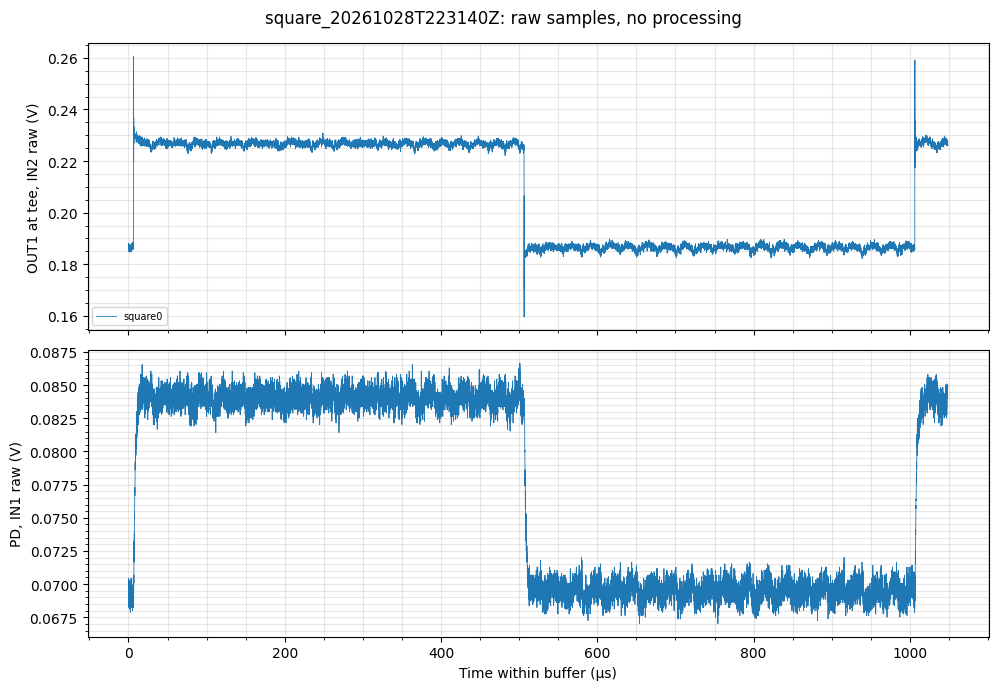

In [47]:
raw_look(step_run)

In [48]:
# Step bandwidth (Decisions 5-7): per edge, then mean and spread over edges.
print("Single pole: x(t) = 1 - exp(-t/tau); 10% at tau*ln(10/9), 90% at tau*ln(10)\n"
      "-> t_10-90 = tau*ln 9 = 2.2 tau;  f_-3dB = 1/(2 pi tau) = ln 9/(2 pi t_10-90) = 0.35/t_10-90\n"
      "Only exact for a single pole: if the edge has a delay, an S-shape or overshoot, this is a single-pole EQUIVALENT.\n")
step_meta = json.loads((step_run / "metadata.json").read_text())
c = step_meta["captures"][0]
dt, f_sq = c["metadata"]["scope"]["sample_interval_s"], c["command"]["actual"]["frequency_hz"]
with np.load(step_run / "raw.npz") as z:
    pd, tee = z[c["name"]] / 8192 * np.array([[step_meta["full_scale_v"]["in1"]], [step_meta["full_scale_v"]["in2"]]])
half = int(0.5 / f_sq / dt)                                     # samples per half-period
edges = np.flatnonzero(np.diff(tee > tee.mean()))               # tee crosses its mean
edges = [e for i, e in enumerate(edges) if i == 0 or e - edges[i - 1] > half // 2]  # one per edge
rise = []
for e in edges:
    if e - int(0.4 * half) < 0 or e + int(0.4 * half) > len(pd):
        continue                                                # need full windows on both sides
    before, after = pd[e - int(0.4 * half):e - int(0.05 * half)].mean(), pd[e + int(0.1 * half):e + int(0.4 * half)].mean()
    times = []
    for frac in (0.1, 0.9):
        level, s = before + frac * (after - before), np.sign(after - before)
        past = np.flatnonzero(s * (pd[e:] - level) >= 0)
        k = e + past[0] if len(past) else None                  # first sample past the level
        times.append(np.nan if k is None else (k - 1 + (level - pd[k - 1]) / (pd[k] - pd[k - 1])) * dt)  # interpolated
    rise.append(times[1] - times[0])
    print(f"edge at {e * dt * 1e6:7.1f} µs: {before:.4f} -> {after:.4f} V, t_10-90 = {rise[-1] * 1e6:.2f} µs, "
          f"tau = {rise[-1] / np.log(9) * 1e6:.2f} µs, f_-3dB = {np.log(9) / (2 * np.pi * rise[-1]) / 1e3:.1f} kHz")
rise = np.array(rise)
step_bandwidth = {"run": step_run.name, "t_10_90_s": rise.tolist(), "f_3db_hz": (np.log(9) / (2 * np.pi * rise)).tolist()}
print(f"\nMean over {len(rise)} edges: t_10-90 = {np.nanmean(rise) * 1e6:.2f} ± {np.nanstd(rise) * 1e6:.2f} µs (std) "
      f"-> single-pole-equivalent f_-3dB ≈ {np.log(9) / (2 * np.pi * np.nanmean(rise)) / 1e3:.1f} kHz")

Single pole: x(t) = 1 - exp(-t/tau); 10% at tau*ln(10/9), 90% at tau*ln(10)
-> t_10-90 = tau*ln 9 = 2.2 tau;  f_-3dB = 1/(2 pi tau) = ln 9/(2 pi t_10-90) = 0.35/t_10-90
Only exact for a single pole: if the edge has a delay, an S-shape or overshoot, this is a single-pole EQUIVALENT.

edge at   506.2 µs: 0.0841 -> 0.0695 V, t_10-90 = 3.65 µs, tau = 1.66 µs, f_-3dB = 95.8 kHz

Mean over 1 edges: t_10-90 = 3.65 ± 0.00 µs (std) -> single-pole-equivalent f_-3dB ≈ 95.8 kHz


<a id="sweep"></a>
### Frequency Response: swept sine (Bode plot)

**Question:** What are the magnitude and phase of the chain's response from 10 Hz up, and where is it 3 dB down?

**Prediction:** Roll-off near 30 kHz (spectrum analyzer knee); more than one pole, so the phase falls past −90°.

**Derivation:** Biased at the crossing, a small sine $V_0\sin 2\pi f t$ gives $\text{PD}(t) \approx \text{const} + |H|\,(dI/dV)\,V_0 \sin(2\pi f t + \phi)$. Each channel's complex amplitude at $f$, over a whole number of cycles with the mean removed, is
$$Z = \frac{2}{N}\sum_n x_n\, e^{-i 2\pi f t_n}, \qquad H(f) = \frac{Z_\text{PD}}{Z_\text{tee}}.$$
Both channels share one buffer, so their common delay cancels. **−3 dB** is where $|H|$ falls to $1/\sqrt 2$ of its flat level (half the power); a single pole gives −45° there.

**Caveats:**
- Bias drift changes the slope $dI/dV$ during the sweep (low frequencies take longest).
- Whole chain, not the crystal alone; electrical pickup into IN1 already matters near 65 kHz.
- Each frequency is a separate buffer: a glitch between buffers shows as one jagged point.
- At 2 MHz, ±8 V asks ≈ 100 V/µs of the 3211; repeat with `peak_v` 0.01 to check the high points are small-signal.
- Safety: ±0.05 V (≈ ±20 V at the EOM), 5 Hz–2 MHz; the bias is ramped once and frequency changes keep it on.

**Notable Decisions:**
- (8) Complex amplitude = single-frequency Fourier sum over whole cycles, mean removed (a software lock-in on raw data).
- (9) −3 dB by linear interpolation in log f at the first point below −3 dB.
- (10) Magnitude and phase relative to the median over 100 Hz–10 kHz; phase unwrapped first. A lone 10 Hz reference had shifted −3 dB by up to 25 kHz. `np.angle` wraps at ±180°; unwrap removes those fake 360° jumps but can *add* one where neighbours truly differ by more than 180°.

**Simplest estimate:** Read the frequency where the magnitude crosses the −3 dB line on the plot.

<!-- Decision log: 8 approved TS 2026-10-28 (asked for a Bode plot); 9 approved TS 2026-10-28 (asked in chat);
10 reference approved TS 2026-10-28; 10 unwrap PENDING (tutor list). -->

In [49]:
# Same bias as the step test; ±0.02 V ≈ ±8 V at the EOM. 10 Hz to 2 MHz, 10 points per decade, ~30 s.
sweep_test = {"offset_v": bias_v, "peak_v": 0.02, "start_hz": 10.0, "stop_hz": 2e6, "points_per_decade": 10, "min_cycles": 10}
sweep_run = rp_run("sweep", wiring="Out1 -> In2 and preamp, preamp -> 3211 -> 4004 EOM", sweep=sweep_test)  # Type what is connected now

INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


f00 ok
f01 ok
f02 ok
f03 ok
f04 ok
f05 ok
f06 ok
f07 ok
f08 ok
f09 ok
f10 ok
f11 ok
f12 ok
f13 ok
f14 ok
f15 ok
f16 ok
f17 ok
f18 ok
f19 ok
f20 ok
f21 ok
f22 ok
f23 ok
f24 ok
f25 ok
f26 ok
f27 ok
f28 ok
f29 ok
f30 ok
f31 ok
f32 ok
f33 ok
f34 ok
f35 ok
f36 ok
f37 ok
f38 ok
f39 ok
f40 ok
f41 ok
f42 ok
f43 ok
f44 ok
f45 ok
f46 ok
f47 ok
f48 ok
f49 ok
f50 ok
f51 ok
f52 ok
f53 ok
completed; cleanup=COMPLETED; saved to /home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/sweep_20261028T223211Z


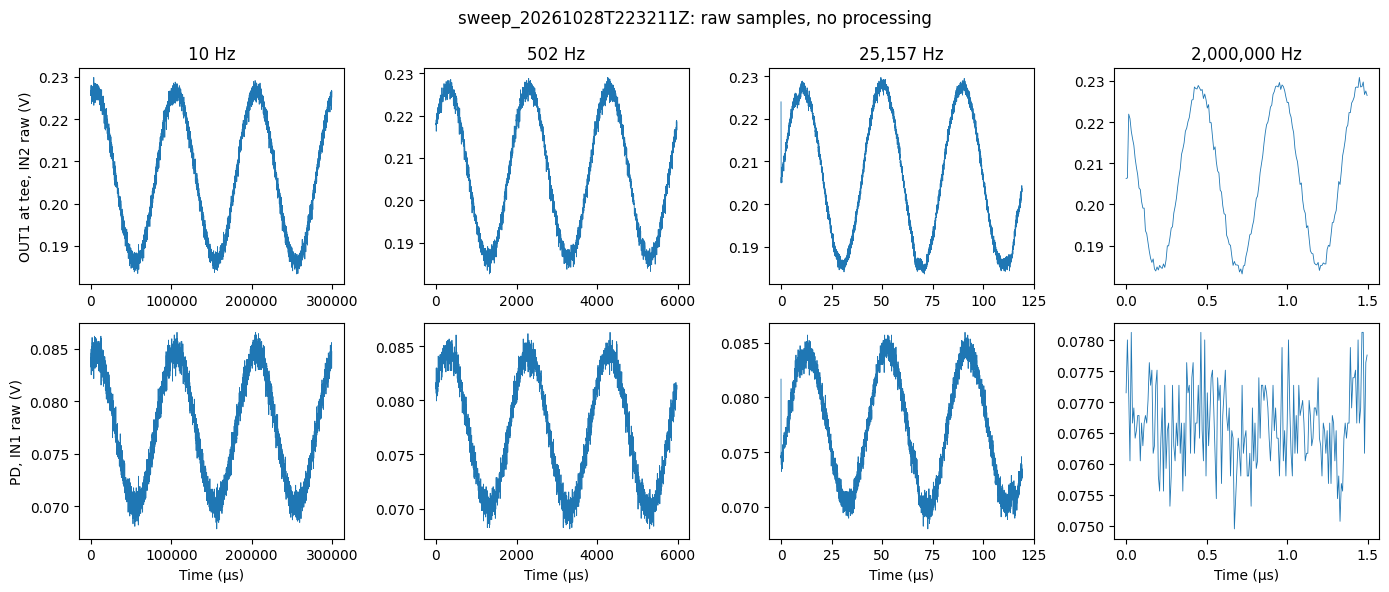

In [50]:
raw_look(sweep_run)

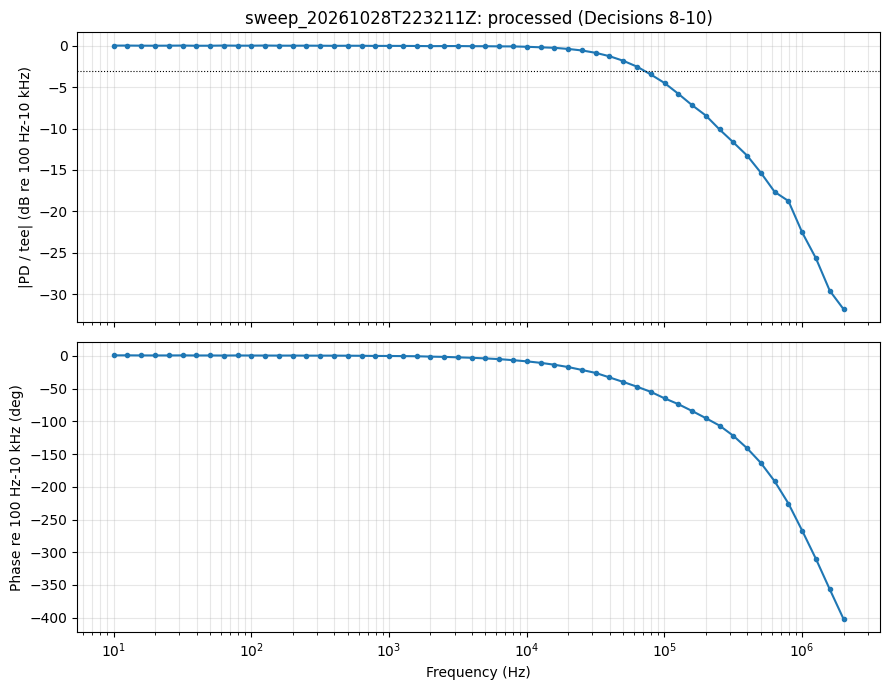

-3 dB at 71.3 kHz (first crossing, interpolated); phase there -51°
Step estimate for comparison: 95.8 kHz


In [51]:
# Bode plot and -3 dB point (Decisions 8-10).
sweep_meta = json.loads((sweep_run / "metadata.json").read_text())
fs = np.array([[sweep_meta["full_scale_v"]["in1"]], [sweep_meta["full_scale_v"]["in2"]]])
freq, H = [], []
with np.load(sweep_run / "raw.npz") as z:
    for c in sweep_meta["captures"]:
        f, dt = c["command"]["actual"]["frequency_hz"], c["metadata"]["scope"]["sample_interval_s"]
        n = int(int(16384 * dt * f) / (f * dt))                  # samples in a whole number of cycles
        x = z[c["name"]][:, :n] / 8192 * fs
        x = x - x.mean(axis=1, keepdims=True)
        Z = 2 / n * (x * np.exp(-2j * np.pi * f * np.arange(n) * dt)).sum(axis=1)  # [PD, tee]
        freq.append(f); H.append(Z[0] / Z[1])
freq, H = np.array(freq), np.array(H)
band = (freq >= 100) & (freq <= 10e3)                        # flat reference band (Decision 10)
mag_db = 20 * np.log10(np.abs(H) / np.median(np.abs(H[band])))
phase_deg = np.degrees(np.unwrap(np.angle(H)))
phase_deg -= np.median(phase_deg[band])
below = np.flatnonzero(mag_db <= -3)
i = below[0] if len(below) else None                         # first point at or below -3 dB
f_3db = np.nan if i is None else 10 ** np.interp(-3, [mag_db[i], mag_db[i - 1]], np.log10([freq[i], freq[i - 1]]))
bode = {"run": sweep_run.name, "freq_hz": freq.tolist(), "mag_db": mag_db.tolist(), "phase_deg": phase_deg.tolist(), "f_3db_hz": f_3db}

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
a1.semilogx(freq, mag_db, "o-", ms=3); a1.axhline(-3, color="k", ls=":", lw=0.8)
a1.set(ylabel="|PD / tee| (dB re 100 Hz-10 kHz)", title=f"{sweep_run.name}: processed (Decisions 8-10)")
a2.semilogx(freq, phase_deg, "o-", ms=3); a2.set(xlabel="Frequency (Hz)", ylabel="Phase re 100 Hz-10 kHz (deg)")
for a in (a1, a2):
    a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()
print(f"-3 dB at {f_3db / 1e3:.1f} kHz (first crossing, interpolated); phase there "
      f"{np.interp(np.log10(f_3db), np.log10(freq), phase_deg):.0f}°")
if "step_bandwidth" in globals():
    print(f"Step estimate for comparison: {np.log(9) / (2 * np.pi * np.mean(step_bandwidth['t_10_90_s'])) / 1e3:.1f} kHz")

<a id="network"></a>
### Frequency Response: FPGA network analyzer

**Question:** The same Bode plot, measured the way the spectrum analyzer does it: fast, dense, over the Red Pitaya's full range.

**Prediction:** Agrees with the stepped sine where both have data; above a few MHz the trace hits the instrument floor.

**Derivation:** Pyrpl's `iq0` is a lock-in on the FPGA. At each $f$ it adds a sine to OUT1 (on top of our DC bias), multiplies the input by $e^{-i2\pi f t}$ and low-pass filters with bandwidth rbw, giving one complex number and no waveform. Two passes, IN1 (PD) then IN2 (tee): $H(f) = Z_\text{PD}/Z_\text{tee}$, so the FPGA's own filters and delays cancel. rbw ≈ f/10 and each point takes $1.5/\text{rbw}$, so low frequencies are slow and high ones fast, like the analyzer.

**Caveats:**
- PD and tee are not measured together: bias drift during the ~25 s PD pass becomes a false slope. The stepped sine is the check.
- No raw waveforms, so harmonics or slew distortion are invisible here.
- 50 MHz is the most the RP can drive and sample, not the trustworthy range: above ~3 MHz the PD channel is gain-independent pickup, and above ~20 MHz the DAC image at 125 MHz − f folds back onto f.
- A ~0.35 µs delay makes the unwrapped phase ambiguous above ~10 MHz at 25 points/decade.
- Safety: ±0.05 V cap, 5 Hz–50 MHz.

**Notable Decisions:**
- (11) Pyrpl NetworkAnalyzer defaults (rbw ≈ f/10 capped at 500 Hz, settle 0.5 and average 1 rbw period; 3× wait on the first point) except a 4.74 Hz input high-pass, since Pyrpl's 50 Hz default would cut our 10 Hz start.
- (12) Same display rules as Decisions 9–10.

**Simplest estimate:** Read the −3 dB crossing off the plot and compare with the stepped-sine points overlaid.

<!-- Decision log: 11 approved TS 2026-10-28; 12 as 10 (reference approved, unwrap PENDING). -->

In [52]:
# Same bias and amplitude as the stepped sine; 25 points/decade from 10 Hz to 50 MHz (~170 points, ~45 s).
network_test = {"offset_v": bias_v, "amplitude_v": 0.02, "start_hz": 10.0, "stop_hz": 50e6, "points_per_decade": 25,
                "q": 10.0, "max_rbw_hz": 500.0}
network_run = rp_run("network", wiring="Out1 -> In2 and preamp, preamp -> 3211 -> 4004 EOM", network=network_test)  # Type what is connected now

INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


in1 done
in2 done
completed; cleanup=COMPLETED; saved to /home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/network_20261028T223259Z


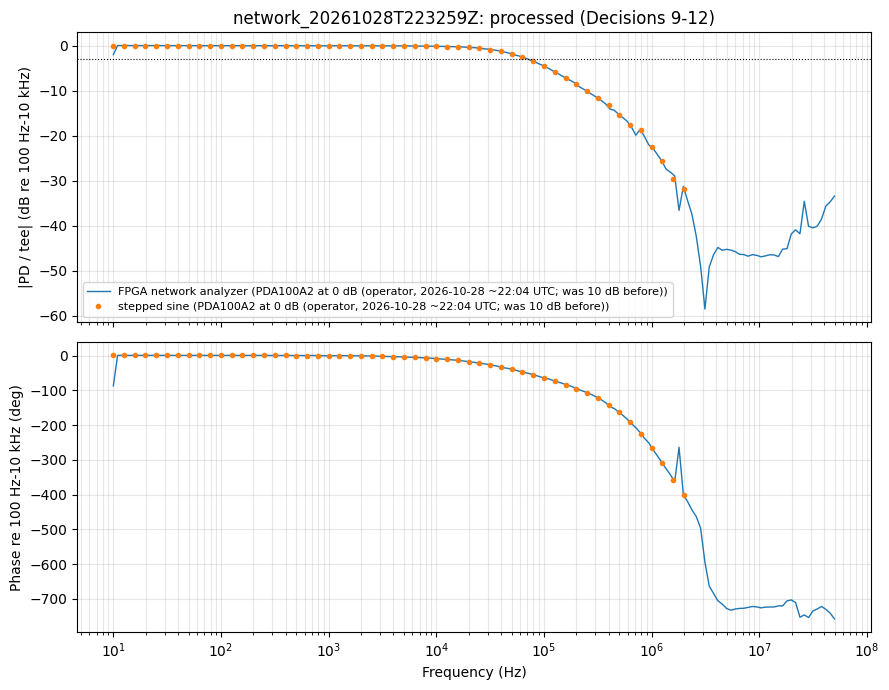

FPGA network analyzer: -3 dB at 71.5 kHz; phase there -51°
Stepped sine: -3 dB at 71.3 kHz


In [53]:
# FPGA network analyzer Bode plot (Decisions 9-12); stepped-sine points overlaid if available.
with np.load(network_run / "raw.npz") as z:
    na_f, na_H = z["na_in1_frequency_hz"], z["na_in1_response"] / z["na_in2_response"]
band = (na_f >= 100) & (na_f <= 10e3)                        # flat reference band (Decision 10)
na_db = 20 * np.log10(np.abs(na_H) / np.median(np.abs(na_H[band])))
na_phase = np.degrees(np.unwrap(np.angle(na_H)))
na_phase -= np.median(na_phase[band])
below = np.flatnonzero(na_db <= -3)
i = below[0] if len(below) else None
na_f_3db = np.nan if i is None else 10 ** np.interp(-3, [na_db[i], na_db[i - 1]], np.log10([na_f[i], na_f[i - 1]]))
network_bode = {"run": network_run.name, "freq_hz": na_f.tolist(), "mag_db": na_db.tolist(), "phase_deg": na_phase.tolist(), "f_3db_hz": na_f_3db}

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
gain = lambda run: json.loads((run / "metadata.json").read_text())["bench"].get("pd_gain", "PD gain not logged")
a1.semilogx(na_f, na_db, "-", lw=1, label=f"FPGA network analyzer ({gain(network_run)})")
a2.semilogx(na_f, na_phase, "-", lw=1)
if "bode" in globals():
    a1.semilogx(bode["freq_hz"], bode["mag_db"], "o", ms=3, label=f"stepped sine ({gain(sweep_run)})")
    a2.semilogx(bode["freq_hz"], bode["phase_deg"], "o", ms=3)
a1.axhline(-3, color="k", ls=":", lw=0.8); a1.legend(fontsize=8)
a1.set(ylabel="|PD / tee| (dB re 100 Hz-10 kHz)", title=f"{network_run.name}: processed (Decisions 9-12)")
a2.set(xlabel="Frequency (Hz)", ylabel="Phase re 100 Hz-10 kHz (deg)")
for a in (a1, a2):
    a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()
print(f"FPGA network analyzer: -3 dB at {na_f_3db / 1e3:.1f} kHz; phase there "
      f"{np.interp(np.log10(na_f_3db), np.log10(na_f), na_phase):.0f}°")
if "bode" in globals():
    print(f"Stepped sine: -3 dB at {bode['f_3db_hz'] / 1e3:.1f} kHz")

<a id="drift"></a>
### Stability & Drift

**Question:** Over a few minutes, how much do the fringe position ($\Gamma_0$), $V_\pi$ and the fringe depth move?

**Prediction:** Crossings slide a few mV per minute, $V_\pi$ creeps up a few mV and levels off, and peak/trough may jump between contrast states.

**Derivation:** In $I = A + B\cos(\Gamma_0 + \pi V/V_\pi)$:
- a crossing sliding sideways is $\Gamma_0$ drift, $\Delta\Gamma_0 = -\pi\,\Delta V_\text{crossing}/V_\pi$;
- a change in crossing *separation* is a change in $V_\pi$;
- peak and trough moving apart is a change in $B$ (contrast); moving together is a change in $A$ (power or offset).

The same 1 Hz Vπ sine, 20 buffers back to back (≈ 3 min). Run it twice with a minute of outputs-off between to see whether the $V_\pi$ creep resets.

**Caveats:**
- Buffers are 8.6 s long and not contiguous; anything faster is averaged in.
- Time is the host clock at each capture request, not a device timestamp.
- Raw peak/trough are noise-inflated extremes (~±2 mV): use them for changes, not absolute contrast.

**Notable Decisions:**
- (13) Per buffer: crossings, $V_\pi$, raw peak and trough; drift reported as last minus first, no fits (a fitted rate would assume the drift is linear).

**Simplest estimate:** Read the first and last points of each panel.

<!-- Decision log: 13 approved TS 2026-10-28. -->

In [ ]:
drift_sine = {"peak_v": 0.48, "frequency_hz": 1.0, "buffers": 20, "settle_s": 2.0}  # ≈ 3 min, same drive as Vπ
drift_run = rp_run("sine", wiring="Out1 -> In2 and preamp, preamp -> 3211 -> 4004 EOM", sine=drift_sine)  # Type what is connected now

INFO:pyrpl.redpitaya:Correct FPGA image detected, skipping reload
INFO:pyrpl.redpitaya:Successfully connected to Redpitaya with hostname 192.168.1.98.


sine0 ok
sine1 ok
sine2 ok
sine3 ok
sine4 ok
sine5 ok
sine6 ok
sine7 ok
sine8 ok


In [56]:
# Drift numbers and plot (Decisions 2, 3, 13).
d = fringe_rows(drift_run)
t = np.array([r["t_s"] for r in d]) / 60
fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
change_mv = lambda key: [(r[key] - d[0][key]) * 1e3 for r in d]   # change since the first buffer, mV
ax[0].plot(t, change_mv("left_v"), "o-", label="left crossing"); ax[0].plot(t, change_mv("right_v"), "o-", label="right crossing")
ax[1].plot(t, change_mv("vpi_tee_v"), "o-")
ax[2].plot(t, change_mv("peak_v"), "o-", label="peak"); ax[2].plot(t, change_mv("trough_v"), "o-", label="trough")
for a, label in zip(ax, ("Crossing shift at tee (mV)", "Vπ change at tee (mV)", "PD extreme change (mV)")):
    a.set_ylabel(label); a.grid(alpha=0.3)
ax[0].legend(fontsize=8); ax[2].legend(fontsize=8); ax[2].set_xlabel("Time since first buffer (min)")
fig.suptitle(f"{drift_run.name}: per-buffer fringe numbers"); plt.tight_layout(); plt.show()

first, last = d[0], d[-1]
shift = (last["right_v"] + last["left_v"] - first["right_v"] - first["left_v"]) / 2
drift = {"run": drift_run.name, "minutes": t[-1], "crossing_shift_tee_v": shift, "gamma0_shift_rad": -np.pi * shift / first["vpi_tee_v"],
         "vpi_change_tee_v": last["vpi_tee_v"] - first["vpi_tee_v"],
         "peak_change_v": last["peak_v"] - first["peak_v"], "trough_change_v": last["trough_v"] - first["trough_v"]}
print(f"Over {t[-1]:.1f} min: crossings moved {shift * 1e3:+.1f} mV (ΔΓ0 = {drift['gamma0_shift_rad']:+.3f} rad), "
      f"Vπ changed {drift['vpi_change_tee_v'] * 1e3:+.1f} mV, peak {drift['peak_change_v'] * 1e3:+.1f} mV, "
      f"trough {drift['trough_change_v'] * 1e3:+.1f} mV")

FileNotFoundError: [Errno 2] No such file or directory: '/home/augustus/Documents/code/repos/epscor-project-tools/experiments/_local/sine_20261028T223411Z/metadata.json'